### V1535 Sco Spectral Index Work

In [1]:
#imports imports imports
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from sympy import diff as dif

from astropy.io import ascii
import astropy.units as u
import astropy.constants as const
from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D
from astropy.modeling import fitting, models
from scipy.stats import chisquare as CHI

In [2]:
#now to get all of the data

In [3]:
data = ([57067.5, 4.55, 4.132, 0.0203],#B
[57067.5, 7.38, 2.786, 0.0128],
[57067.5, 28.2, 0.819, 0.0575],
[57067.5, 36.5, 0.675, 0.0834],

        [57071.5, 13.5, 0.416, 0.0175], #B
[57071.5, 17.4, 0.344, 0.0213],
[57071.5, 28.2, 0.295, 0.0505],
[57071.5, 36.5, 0.376, 0.0714],

[57072.5, 1.26, 1.57, 0.0765], #B
[57072.5, 1.74, 1.21, 0.0728],
[57072.5, 4.55, 0.65, 0.0168],
[57072.5, 7.38, 0.439, 0.0126],

[57072.5, 4.87, 0.484, 0.0505], #VLBA

[57077.6, 13.5, 0.385, 0.0163], #B
[57077.6, 17.4, 0.456, 0.02],
[57077.6, 28.2, 0.785, 0.0485],
[57077.6, 36.5, 0.845, 0.0758],

[57077.7, 4.87, 0.155, 0.0409], #VLBA

[57082.5, 1.26, 0.0142, 0.101], #B
[57082.5, 1.74, 0.12, 0.0655],
[57082.5, 4.55, 0.221, 0.0181],
[57082.5, 7.38, 0.192, 0.0157],

[57088.5, 13.5, 0.585, 0.0166], #B
[57088.5, 17.4, 0.755, 0.0207],
[57088.5, 28.2, 1.15, 0.0462],
[57088.5, 36.5, 1.68, 0.071],

[57091.4, 1.26, 0.153, 0.0738], #B
[57091.4, 1.74, 0.11, 0.0538],
[57091.4, 4.55, 0.455, 0.0187],
[57091.4, 7.38, 0.536, 0.0136],

[57106.42, 13.5, 0.267, 0.0126], #B
[57106.42, 17.4, 0.299, 0.0143],
[57106.42, 28.2, 0.348, 0.0405],
[57106.42, 36.5, 0.186, 0.0551],

[57106.47, 1.26, 0.273, 0.112], #B
[57106.47, 1.74, 0.163, 0.0597],
[57106.47, 4.55, 0.222, 0.0161],
[57106.47, 7.38, 0.253, 0.012],

[57119.41, 13.5, 0.457, 0.0248], #B
[57119.41, 17.4, 0.399, 0.0182],
[57119.41, 28.2, 0.323, 0.0446],
[57119.41, 36.5, 0.276, 0.0602],

[57120.57, 1.26, 0.873, 0.1], #B
[57120.57, 1.74, 0.661, 0.0562],
[57120.57, 4.55, 0.483, 0.0191],
[57120.57, 7.38, 0.374, 0.0138],

[57130.35, 1.26, 0.444, 0.0813], #B
[57130.35, 1.74, 0.258, 0.056],
[57130.35, 4.55, 0.256, 0.0172],
[57130.35, 7.38, 0.228, 0.0117],

[57131.33, 13.5, 0.209, 0.0156], #B
[57131.33, 17.4, 0.167, 0.0221],
[57131.33, 28.2, 0.173, 0.0482],
[57131.33, 36.5, 0.0395, 0.0833],

[57143.3, 1.26, -0.0723, 0.106], #B
[57143.3, 1.74, 0.165, 0.0711],
[57143.3, 4.55, 0.17, 0.0183],
[57143.3, 7.38, 0.139, 0.0144],

[57143.34, 13.5, 0.129, 0.0168], #B
[57143.34, 17.4, 0.164, 0.0216],
[57143.34, 28.2, 0.174, 0.0523],
[57143.34, 36.5, 0.0153, 0.0753],

[57158.3, 1.26, -0.152, 0.177], #B_> BnA
[57158.3, 1.74, 0.101, 0.0784],
[57158.3, 4.55, 0.0727, 0.023],
[57158.3, 7.38, 0.0708, 0.0171],
[57158.3, 13.5, 0.0518, 0.0175],
[57158.3, 16.5, 0.0217, 0.0214],
[57158.3, 29.5, 0.0401, 0.0362],
[57158.3, 35, -0.00361, 0.045],

[57187.2, 1.26, 0.277, 0.116], #BnA _> A
[57187.2, 1.74, -0.0505, 0.0776],
[57187.2, 5, 0.0194, 0.0204],
[57187.2, 7, 0.044, 0.0223],
[57187.2, 13.5, 0.0587, 0.0157],
[57187.2, 16.5, 0.0569, 0.021],
[57187.2, 29.5, 0.13, 0.0446],
[57187.2, 35, -0.0206, 0.0588],

#57360.7	1.26	XX	XX #D
#57360.7	1.74	XX	XX
[57360.7, 5, 0.0795, 0.031],
[57360.7, 7, 0.0561, 0.022],
[57360.7, 13.5, -0.0000599, 0.0196],
[57360.7, 16.5, -0.000577, 0.0199],
[57360.7, 29.6, -0.0157, 0.051],
[57360.7, 35, 0.0632, 0.0608],)



df =  pd.DataFrame(data, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

In [4]:
#splitting it up by day

In [4]:


E1 = ([57067.5, 4.55, 4.132, 0.0203],#B
[57067.5, 7.38, 2.786, 0.0128],
[57067.5, 28.2, 0.819, 0.0575],
[57067.5, 36.5, 0.675, 0.0834],)

E2 = ( [57071.5, 13.5, 0.416, 0.0175], #B
[57071.5, 17.4, 0.344, 0.0213],
[57071.5, 28.2, 0.295, 0.0505],
[57071.5, 36.5, 0.376, 0.0714],				
[57072.5, 1.26, 1.57, 0.0765], #B
[57072.5, 1.74, 1.21, 0.0728],
[57072.5, 4.55, 0.65, 0.0168],
[57072.5, 7.38, 0.439, 0.0126],
[57072.5, 4.87, 0.484, 0.0505], #VLBA
    )

E4 = ([57077.6, 13.5, 0.385, 0.0163], #B
[57077.6, 17.4, 0.456, 0.02],
[57077.6, 28.2, 0.785, 0.0485],
[57077.6, 36.5, 0.845, 0.0758],

[57077.7, 4.87, 0.155, 0.0409], #VLBA
    )

E5 = ([57082.5, 1.26, 0.0142, 0.101], #B
[57082.5, 1.74, 0.12, 0.0655],
[57082.5, 4.55, 0.221, 0.0181],
[57082.5, 7.38, 0.192, 0.0157],				
    )

E6 = (	[57088.5, 13.5, 0.585, 0.0166], #B
[57088.5, 17.4, 0.755, 0.0207],
[57088.5, 28.2, 1.15, 0.0462],
[57088.5, 36.5, 1.68, 0.071],			
    )

E7 = ([57091.4, 1.26, 0.153, 0.0738], #B
[57091.4, 1.74, 0.11, 0.0538],
[57091.4, 4.55, 0.455, 0.0187],
[57091.4, 7.38, 0.536, 0.0136],
    )

E8 = ([57106.42, 13.5, 0.267, 0.0126], #B
[57106.42, 17.4, 0.299, 0.0143],
[57106.42, 28.2, 0.348, 0.0405],
[57106.42, 36.5, 0.186, 0.0551],

[57106.47, 1.26, 0.273, 0.112], #B
[57106.47, 1.74, 0.163, 0.0597],
[57106.47, 4.55, 0.222, 0.0161],
[57106.47, 7.38, 0.253, 0.012],
    )

E9 = ([57119.41, 13.5, 0.457, 0.0248], #B
[57119.41, 17.4, 0.399, 0.0182],
[57119.41, 28.2, 0.323, 0.0446],
[57119.41, 36.5, 0.276, 0.0602],
[57120.57, 1.26, 0.873, 0.1], #B
[57120.57, 1.74, 0.661, 0.0562],
[57120.57, 4.55, 0.483, 0.0191],
[57120.57, 7.38, 0.374, 0.0138],
    )

E11 = ([57130.35, 1.26, 0.444, 0.0813], #B
[57130.35, 1.74, 0.258, 0.056],
[57130.35, 4.55, 0.256, 0.0172],
[57130.35, 7.38, 0.228, 0.0117],
[57131.33, 13.5, 0.209, 0.0156], #B
[57131.33, 17.4, 0.167, 0.0221],
[57131.33, 28.2, 0.173, 0.0482],
[57131.33, 36.5, 0.0395, 0.0833],		
    )


E13 =([57143.3, 1.26, -0.0723, 0.106], #B
[57143.3, 1.74, 0.165, 0.0711],
[57143.3, 4.55, 0.17, 0.0183],
[57143.3, 7.38, 0.139, 0.0144],

[57143.34, 13.5, 0.129, 0.0168], #B
[57143.34, 17.4, 0.164, 0.0216],
[57143.34, 28.2, 0.174, 0.0523],
[57143.34, 36.5, 0.0153, 0.0753],
    )

E14 = ([57158.3, 1.26, -0.152, 0.177], #B_> BnA
[57158.3, 1.74, 0.101, 0.0784],
[57158.3, 4.55, 0.0727, 0.023],
[57158.3, 7.38, 0.0708, 0.0171],
[57158.3, 13.5, 0.0518, 0.0175],
[57158.3, 16.5, 0.0217, 0.0214],
[57158.3, 29.5, 0.0401, 0.0362],
[57158.3, 35, -0.00361, 0.045],
    )

E15 = ([57187.2, 1.26, 0.277, 0.116], #BnA _> A
[57187.2, 1.74, -0.0505, 0.0776],
[57187.2, 5, 0.0194, 0.0204],
[57187.2, 7, 0.044, 0.0223],
[57187.2, 13.5, 0.0587, 0.0157],
[57187.2, 16.5, 0.0569, 0.021],
[57187.2, 29.5, 0.13, 0.0446],
[57187.2, 35, -0.0206, 0.0588],
				
    )

E16 = (#57360.7	1.26	XX	XX #D
#57360.7	1.74	XX	XX
[57360.7, 5, 0.0795, 0.031],
[57360.7, 7, 0.0561, 0.022],
[57360.7, 13.5, -0.0000599, 0.0196],
[57360.7, 16.5, -0.000577, 0.0199],
[57360.7, 29.6, -0.0157, 0.051],
[57360.7, 35, 0.0632, 0.0608],)

In [5]:
df1 =  pd.DataFrame(E1, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df2 =  pd.DataFrame(E2, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])


df4 =  pd.DataFrame(E4, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df5 =  pd.DataFrame(E5, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df6 =  pd.DataFrame(E6, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df7 =  pd.DataFrame(E7, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df8 =  pd.DataFrame(E8, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df9 =  pd.DataFrame(E9, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])


df11 =  pd.DataFrame(E11, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])



df13 =  pd.DataFrame(E13, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df14 =  pd.DataFrame(E14, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df15 =  pd.DataFrame(E15, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df16 =  pd.DataFrame(E16, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

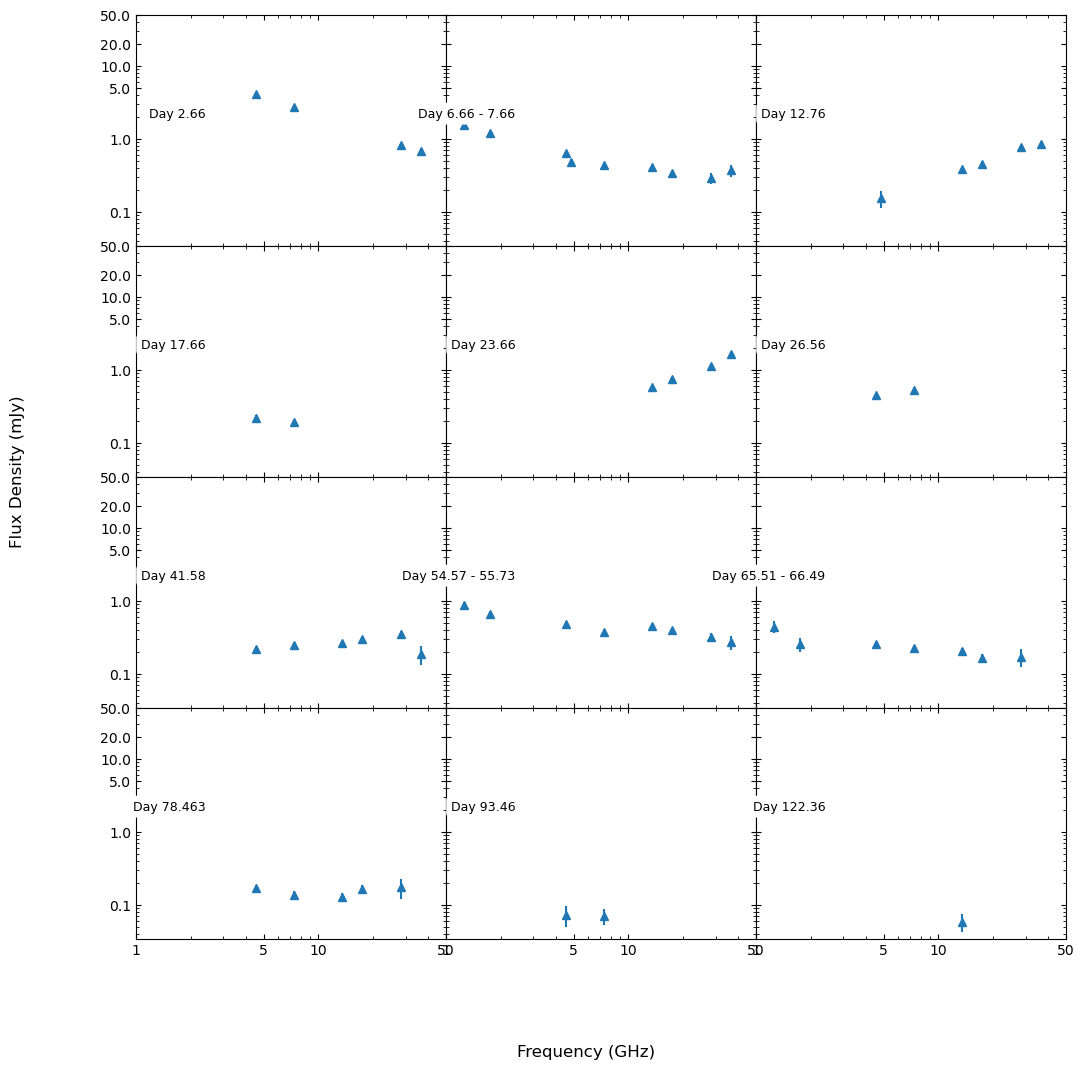

In [6]:
dfs = [df1, df2, df4, df5, df6, df7, df8, df9,
       df11, df13, df14, df15, df16]


#the days by the list so they can all be defined
annotations = ['Day 2.66', 'Day 6.66 - 7.66', 'Day 12.76', 'Day 17.66', 'Day 23.66',
               'Day 26.56', 'Day 41.58', 'Day 54.57 - 55.73', 'Day 65.51 - 66.49',
               'Day 78.463', 'Day 93.46', 'Day 122.36', 'Day 295.86' ]

#making the figure (4,4) is the (rows, columns)
fig, ax = plt.subplots(4, 3, sharex='all', sharey='all')
fig.set_size_inches(12, 12)
fig.subplots_adjust(hspace=0, wspace=0)

#loop for each of the datasets
for idx, (df, label) in enumerate(zip(dfs, annotations)):
    row, col = divmod(idx, 3)
    mask = df['Flux Density (mJy)'] > 3 * df['Uncertainty (mJy)'] #don't show the non-detections
    if mask.any():
        ax[row, col].errorbar(df['Freq (GHz)'][mask], df['Flux Density (mJy)'][mask], yerr=df['Uncertainty (mJy)'][mask], fmt='^')
        ax[row, col].set_xscale('log')
        ax[row, col].set_yscale('log')
        ax[row, col].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
        ax[row, col].set_yticks([.1, 1, 5, 10, 20, 50], labels=['0.1','1.0', '5.0', '10.0', '20.0', '50.0'])
        ax[row, col].annotate(label, xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
        ax[row, col].tick_params(axis='both', which='both', direction='in', top=True, right=True)

fig.supxlabel("Frequency (GHz)")
fig.supylabel("Flux Density (mJy)")
plt.show();

# Finding the alpha for each day

In [7]:
def error(err, freq, flux):
    yerr = []
    for i in range(len(freq)):
        if freq[i] < 10:
            pl = np.sqrt(err[i]**2 + (flux[i]*0.05)**2)
            yerr.append(pl)
        else:
            pl =np.sqrt(err[i]**2 + (flux[i]*0.1)**2)
            yerr.append(pl)

    return(yerr)



#### Day 2.7

In [8]:
mask = df1['Flux Density (mJy)'] > 3 * df1['Uncertainty (mJy)']  # apply detection threshold
if mask.any():
    x1 = df1['Freq (GHz)'][mask].values.tolist()
    y1 = df1['Flux Density (mJy)'][mask].values.tolist()
    yerr1 = df1['Uncertainty (mJy)'][mask].values.tolist()


In [9]:
yerr1 = error(yerr1, x1, y1)

In [10]:
PL1 =  PowerLaw1D(amplitude = y1[0], x_0= x1[0], alpha= 1,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        'x_0': (min(x1), max(x1)),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    }) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 

fit1 = fitting.LevMarLSQFitter(calc_uncertainties=True)

    #Fit the data w/o weights
fit_model1 = fit1(PL1, x1, y1, maxiter=10000)

    #weight is 1/error^2
y_weight1 = 1/ (np.power(yerr1,2))  

    # fit the data using the uncertainties as weights
fit_model_weights1 = fit1(PL1, x1, y1, weights=y_weight1, maxiter=10000)

fit_model_weights1

<PowerLaw1D(amplitude=4.21996131, x_0=4.55, alpha=0.88792972)>

In [11]:
fit1.fit_info

{'nfev': 24,
 'fvec': array([ 2.04107156, -2.01090903,  1.6305434 , -0.92870658]),
 'fjac': array([[ 2.02238983e+02, -3.08915245e+01, -2.75229918e+01,
          5.74968591e-01],
        [-3.28804196e+01, -2.91801648e+01, -2.52501098e+01,
         -6.00374696e-01],
        [-2.92950101e+01, -2.59982455e+01, -3.97205465e-15,
          4.47213595e-01]]),
 'ipvt': array([3, 1, 2], dtype=int32),
 'qtf': array([-9.55106696e-05, -2.61427950e-04,  2.47025652e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 5.90219226e+29, -6.62456022e+29,  1.83868482e+13],
        [-6.62456022e+29,  7.43533862e+29, -2.06372103e+13],
        [ 1.83868482e+13, -2.06372103e+13,  1.22377943e-03]]),
 'njev': 14,
 'cov_x': array([[ 5.03132267e+28, -5.64710510e+28,  1.56738653e+12],
        [-5.64710510e+28,  6.33825300e+28, -1.75921860e+12],
        [ 1.56738653e+12, -1.75921860e+12,  1.04321054e-0

In [12]:
fvec1 = np.array([ 2.04099435, -2.01100142,  1.63051861, -0.92871972])
var1 = np.var(fvec1)

param_cov1= np.array([[ 1.25357056e+28, -1.40938350e+28, -1.45799099e+12],
        [-1.40938350e+28,  1.58456325e+28,  1.63921242e+12],
        [-1.45799099e+12,  1.63921242e+12,  2.24901122e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag1 = stand(param_cov1*var1) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print("The standard deviation is", diag1[2]) #Just showing the standard devation on the slope


The standard deviation is 0.025535181269153717


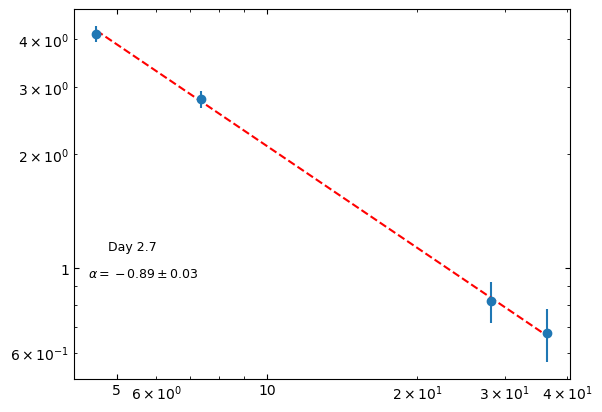

In [13]:
fig,ax = plt.subplots()
mask = df1['Flux Density (mJy)'] > 3 * df1['Uncertainty (mJy)']  # apply detection threshold
mask2 = df1['Flux Density (mJy)'] < 3 * df1['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df1['Freq (GHz)'][mask], df1['Flux Density (mJy)'][mask], yerr=yerr1, fmt='o')
    ax.scatter(df1['Freq (GHz)'][mask2], (df1['Flux Density (mJy)'][mask2] + 3*df1['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 2.7', xy=(60, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df1['Freq (GHz)'][mask], fit_model_weights1(df1['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.89 \\pm 0.03}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    #ax.annotate('${\u03B1 2 =  \\pm }$', xy=(90, 60), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
plt.show();

-----

#### Day 6.66 - 7.66 (df 2)

In [14]:
mask = df2['Flux Density (mJy)'] > 3 * df2['Uncertainty (mJy)']  # apply detection threshold
if mask.any():
    x2 = df2['Freq (GHz)'][mask].values.tolist()
    y2 = df2['Flux Density (mJy)'][mask].values.tolist()
    yerr2 = df2['Uncertainty (mJy)'][mask].values.tolist()


In [15]:
yerr2 = error(yerr2, x2, y2)

In [16]:
PL2 =  PowerLaw1D(amplitude = y2[0], x_0= x2[0], alpha= .5,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        'x_0': (min(x2), max(x2)),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    }) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 

fit2 = fitting.LevMarLSQFitter(calc_uncertainties=True)

    #Fit the data w/o weights
fit_model2 = fit2(PL2, x2, y2)

    #weight is 1/error^2
y_weight2 = 1/ (np.power(yerr2,2))  

    # fit the data using the uncertainties as weights
fit_model_weights2 = fit2(PL2, x2, y2, weights=y_weight2)

fit_model_weights2

<PowerLaw1D(amplitude=0.47925073, x_0=6.9660551, alpha=0.55850283)>

In [17]:
fit2.fit_info

{'nfev': 14,
 'fvec': array([-41.63806608, -34.55970036, -22.07713977, -28.55885763,
        -27.01562127, -18.97500681, -31.41153616,  39.10065952,
         32.30685097]),
 'fjac': array([[-1.92646039e+03, -5.87352096e+01, -7.40220894e+01,
          3.16089294e-02,  1.12276160e-01,  1.25716036e-01,
          4.91964912e-01,  7.84651922e-01,  2.02163523e-01],
        [-5.87352096e+01,  3.81212893e+02,  1.82037913e-14,
          1.23348848e-01, -4.77200849e-01, -4.36048429e-01,
         -5.61081753e-01,  2.42060017e-02, -1.97287983e-01],
        [-7.40220894e+01, -1.17216094e-16,  7.11832660e-15,
          6.38366464e-02, -5.60925614e-03, -5.12553013e-03,
         -6.59523401e-03, -9.97903354e-01, -2.31902109e-03]]),
 'ipvt': array([1, 3, 2], dtype=int32),
 'qtf': array([ 2.87796364e-03, -3.85753842e-03,  6.84721844e+01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 4.31

In [18]:
fvec2 = np.array([-41.63784297, -34.55948563, -22.0770795 , -28.55883465,
        -27.01533456, -18.97470779, -31.41062262,  39.10191066,
         32.30721892])
var2 = np.var(fvec2)


param_cov2 = np.array([[ 1.43671710e+25, -5.11253067e+26, -6.75364842e+08],
        [-5.11253067e+26,  1.81928438e+28,  2.40327303e+10],
        [-6.75364842e+08,  2.40327303e+10,  6.91293106e-06]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag2 = stand(param_cov2*var2) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print("The standard deviation is", diag2[2]) #Just showing the standard devation on the slope


The standard deviation is 0.0729060137909106


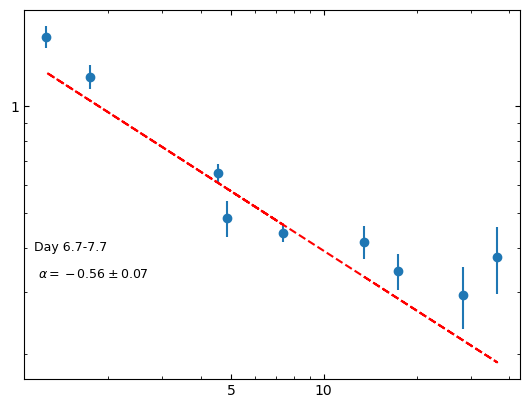

In [19]:
fig,ax = plt.subplots()
mask = df2['Flux Density (mJy)'] > 3 * df2['Uncertainty (mJy)']  # apply detection threshold
mask2 = df2['Flux Density (mJy)'] < 3 * df2['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df2['Freq (GHz)'][mask], df2['Flux Density (mJy)'][mask], yerr=yerr2, fmt='o')
    ax.scatter(df2['Freq (GHz)'][mask2], (df2['Flux Density (mJy)'][mask2] + 3*df2['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 6.7-7.7', xy=(60, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df2['Freq (GHz)'][mask], fit_model_weights2(df2['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.56 \\pm 0.07}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

#### Day 12.76

In [20]:
mask = df4['Flux Density (mJy)'] > 3 * df4['Uncertainty (mJy)']  # apply detection threshold
if mask.any():
    x4 = df4['Freq (GHz)'][mask].values.tolist()
    y4 = df4['Flux Density (mJy)'][mask].values.tolist()
    yerr4 = df4['Uncertainty (mJy)'][mask].values.tolist()


In [21]:
yerr4 = error(yerr4, x4, y4)

In [22]:
PL4 =  PowerLaw1D(amplitude = y4[0], x_0= x4[0], alpha= .5,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        'x_0': (min(x4), max(x4)),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    }) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 

fit4 = fitting.LevMarLSQFitter(calc_uncertainties=True)

    #Fit the data w/o weights
fit_model4 = fit4(PL4, x4, y4, maxiter=10000)

    #weight is 1/error^2
y_weight4 = 1/ (np.power(yerr4,2))  

    # fit the data using the uncertainties as weights
fit_model_weights4 = fit4(PL4, x4, y4, weights=y_weight4, maxiter=10000)

fit_model_weights4

<PowerLaw1D(amplitude=0.74036931, x_0=29.29905622, alpha=-0.86672977)>

In [23]:
fit4.fit_info

{'nfev': 20,
 'fvec': array([-3.8628409 ,  6.17367066, -8.07598399,  3.93547376,  0.75550331]),
 'fjac': array([[-4.33495449e+02, -2.14751116e+02,  9.49430180e+00,
          2.16581353e-01,  2.81050884e-01],
        [-2.14751116e+02,  1.35105520e+02, -3.91995050e-15,
          4.79231737e-01, -7.22896234e-01],
        [ 9.49430180e+00, -7.45453330e-16,  7.92206217e-16,
          7.79245194e-01, -6.14878243e-01]]),
 'ipvt': array([1, 3, 2], dtype=int32),
 'qtf': array([-5.92516211e-05,  1.66195058e-10,  3.47843554e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[5.13308269e+28, 2.34368786e+30, 1.29314473e+13],
        [2.34368786e+30, 1.07009240e+32, 5.90430311e+14],
        [1.29314473e+13, 5.90430311e+14, 6.93692159e-03]]),
 'njev': 8,
 'cov_x': array([[7.64329264e+26, 3.48981173e+28, 1.92552589e+11],
        [3.48981173e+28, 1.59339521e+30, 8.79165977e+12],
        [

In [24]:
fvec4 = np.array([-3.8628409 ,  6.17367066, -8.07598399,  3.93547376,  0.75550331])
var4 = np.var(fvec4)


param_cov4= np.array([[7.64329264e+26, 3.48981173e+28, 1.92552589e+11],
        [3.48981173e+28, 1.59339521e+30, 8.79165977e+12],
        [1.92552589e+11, 8.79165977e+12, 1.03292553e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag4 = stand(param_cov4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print("The standard deviation is", diag4[2]) #Just showing the standard devation on the slope


The standard deviation is 0.05263080119109629


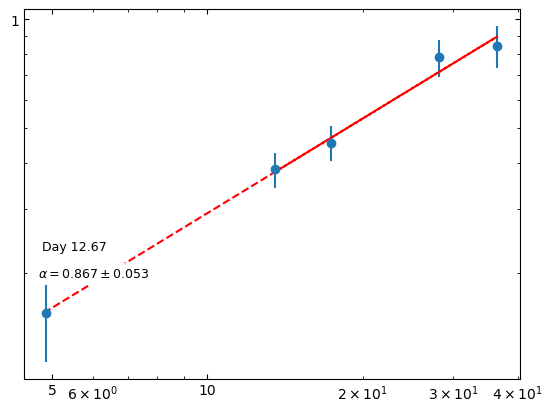

In [25]:
fig,ax = plt.subplots()
mask = df4['Flux Density (mJy)'] > 3 * df4['Uncertainty (mJy)']  # apply detection threshold
mask2 = df4['Flux Density (mJy)'] < 3 * df4['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df4['Freq (GHz)'][mask], df4['Flux Density (mJy)'][mask], yerr=yerr4, fmt='o')
    ax.scatter(df4['Freq (GHz)'][mask2], (df4['Flux Density (mJy)'][mask2] + 3*df4['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 12.67', xy=(60, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df4['Freq (GHz)'][mask], fit_model_weights4(df4['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.867 \\pm 0.053}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

#### Day 17.66

In [26]:
#This one only has two points

mask = df5['Flux Density (mJy)'] > 3 * df5['Uncertainty (mJy)']  # apply detection threshold
if mask.any():
    x5 = df5['Freq (GHz)'][mask].values.tolist()
    y5 = df5['Flux Density (mJy)'][mask].values.tolist()
    yerr5 = df5['Uncertainty (mJy)'][mask].values.tolist()


In [27]:
yerr5 = error(yerr5, x5, y5)

In [28]:
fit5 = fitting.LevMarLSQFitter(calc_uncertainties=True)

PL5 =  PowerLaw1D(amplitude = y5[0], x_0= x5[0], alpha= 0,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        #'x_0': (x3[0], x3[0]),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    },
                 fixed={'x_0': True}) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 


    #Fit the data w/o weights
fit_model5 = fit5(PL5, x5, y5)

    #weight is 1/error^2#y_weight5 = 1/ (np.power(yerr5,2))  

    # fit the data using the uncertainties as weights
fit_model_weights5 = fit5(PL5, x5, y5)#, weights=y_weight5)

fit_model_weights5

<PowerLaw1D(amplitude=0.221, x_0=4.55, alpha=0.29084746)>

In [29]:
fit5.fit_info

{'nfev': 5,
 'fvec': array([0., 0.]),
 'fjac': array([[-1.32467947,  0.65584038],
        [ 0.06090141,  0.07010006]]),
 'ipvt': array([1, 2], dtype=int32),
 'qtf': array([-1.24506014e-10, -1.43311610e-10]),
 'message': 'The relative error between two consecutive iterates is at most 0.000000',
 'ierr': 2,
 'param_jac': None,
 'param_cov': None,
 'njev': 4,
 'cov_x': array([[  1.        ,   9.35577485],
        [  9.35577485, 203.49944302]])}

In [30]:
#taking fvec
fvec5 = np.array([0., 0.])
var5 = np.var(fvec5)

#taking cov_x
cov_x5 = np.array([[1.07328312e-07, 1.00413952e-06],
        [1.00413952e-06, 1.64404641e-05]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    #sd3 = np.sqrt(diag[2])
    return(sd1,sd2)#,sd3)

diag5 = stand(cov_x5)#*var5) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag5[1]) #Just showing the standard deviation on the slope


The error/standard deviation is 0.004054684217050694


In [31]:
#Error on alpha for only two data points
def two_points(Flux, Freq, Err):
    
    alpha = (np.log10(Flux[0]/Flux[1])) / (np.log10(Freq[0]/Freq[1]))
    
    
    der_s1 = 1 / (Flux[0] * np.log(Freq[0]/Freq[1]))
    der_s2 = -1 / (Flux[1] * np.log(Freq[0]/Freq[1]))
    
    
    err_alph_squared = (der_s1)**2 * (Err[0]**2) + (der_s2)**2 * (Err[1]**2) 
    err_alph = np.sqrt(err_alph_squared)
    
    return(alpha, err_alph)

In [32]:
alpha_err5 = two_points(y5,x5,yerr5)
print(alpha_err5)

(-0.29084746179610177, 0.2804219056541765)


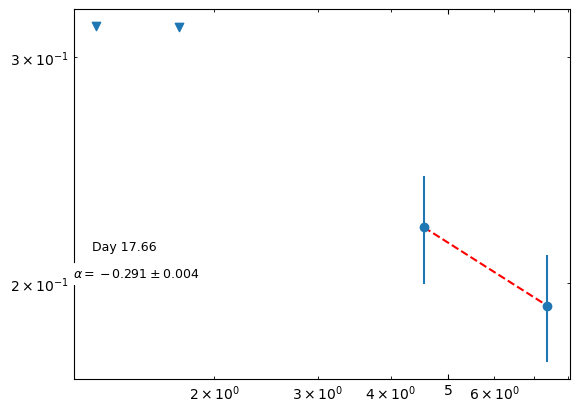

In [33]:
fig,ax = plt.subplots()
mask = df5['Flux Density (mJy)'] > 3 * df5['Uncertainty (mJy)']  # apply detection threshold
mask2 = df5['Flux Density (mJy)'] < 3 * df5['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df5['Freq (GHz)'][mask], df5['Flux Density (mJy)'][mask], yerr=yerr5, fmt='o')
    ax.scatter(df5['Freq (GHz)'][mask2], (df5['Flux Density (mJy)'][mask2] + 3*df5['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 17.66', xy=(60, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df5['Freq (GHz)'][mask], fit_model_weights5(df5['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.291 \\pm 0.004}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

#### Day 23.66

In [34]:
mask = df6['Flux Density (mJy)'] > 3 * df6['Uncertainty (mJy)']  # apply detection threshold
if mask.any():
    x6 = df6['Freq (GHz)'][mask].values.tolist()
    y6 = df6['Flux Density (mJy)'][mask].values.tolist()
    yerr6 = df6['Uncertainty (mJy)'][mask].values.tolist()


In [35]:
yerr6 = error(yerr6, x6, y6)

In [36]:
PL6 =  PowerLaw1D(amplitude = y6[0], x_0= x6[0], alpha= -1,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        'x_0': (min(x6), max(x6)),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    }) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 

fit6 = fitting.LevMarLSQFitter(calc_uncertainties=True)

    #Fit the data w/o weights
fit_model6 = fit6(PL6, x6, y6, maxiter=10000)

    #weight is 1/error^2
y_weight6 = 1/ (np.power(yerr6,2))  

    # fit the data using the uncertainties as weights
fit_model_weights6 = fit6(PL6, x6, y6, weights=y_weight6, maxiter=10000)

fit_model_weights6

<PowerLaw1D(amplitude=0.59542468, x_0=13.74584328, alpha=-0.98025691)>

In [37]:
fit6.fit_info

{'nfev': 7,
 'fvec': array([-0.00434037, -0.78139801,  3.5368173 , -3.88191752]),
 'fjac': array([[-3.68515505e+02,  4.33322537e+01,  1.56471317e+01,
          2.12065666e-01],
        [ 4.33322537e+01,  6.46001264e+01,  4.58024169e-15,
          6.26695947e-01],
        [ 1.56471317e+01,  1.92217490e-15, -1.42284406e-15,
          3.75656779e-01]]),
 'ipvt': array([1, 3, 2], dtype=int32),
 'qtf': array([-2.18072198e-04, -1.45284424e-06, -2.39974853e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 2.51028148e+28,  5.91212281e+29, -1.75915044e+13],
        [ 5.91212281e+29,  1.39240147e+31, -4.14308656e+14],
        [-1.75915044e+13, -4.14308656e+14,  1.90825398e-02]]),
 'njev': 4,
 'cov_x': array([[ 8.90519302e+26,  2.09731838e+28, -6.24056480e+11],
        [ 2.09731838e+28,  4.93952729e+29, -1.46975492e+13],
        [-6.24056480e+11, -1.46975492e+13,  6.76950781e-04]

In [38]:
#taking fvec
fvec6 = np.array([-0.00434037, -0.78139801,  3.5368173 , -3.88191752])
var6 = np.var(fvec6)



param_cov6= np.array([[ 8.90519302e+26,  2.09731838e+28, -6.24056480e+11],
        [ 2.09731838e+28,  4.93952729e+29, -1.46975492e+13],
        [-6.24056480e+11, -1.46975492e+13,  6.76950781e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag6 = stand(param_cov6*var6) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print("The standard deviation is", diag6[2]) #Just showing the standard devation on the slope


The standard deviation is 0.06867699636648604


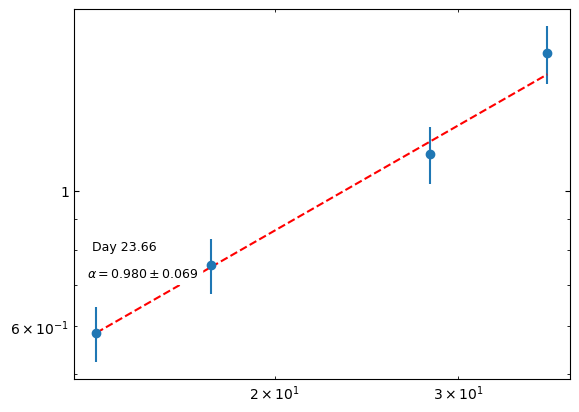

In [39]:
fig,ax = plt.subplots()
mask = df6['Flux Density (mJy)'] > 3 * df6['Uncertainty (mJy)']  # apply detection threshold
mask2 = df6['Flux Density (mJy)'] < 3 * df6['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df6['Freq (GHz)'][mask], df6['Flux Density (mJy)'][mask], yerr=yerr6, fmt='o')
    ax.scatter(df6['Freq (GHz)'][mask2], (df6['Flux Density (mJy)'][mask2] + 3*df6['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 23.66', xy=(60, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df6['Freq (GHz)'][mask], fit_model_weights6(df6['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.980 \\pm 0.069}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

#### Day 26.56

In [40]:
mask = df7['Flux Density (mJy)'] > 3 * df7['Uncertainty (mJy)']  # apply detection threshold
if mask.any():
    x7 = df7['Freq (GHz)'][mask].values.tolist()
    y7 = df7['Flux Density (mJy)'][mask].values.tolist()
    yerr7 = df7['Uncertainty (mJy)'][mask].values.tolist()


In [41]:
yerr7 = error(yerr7, x7,y7)

In [42]:
fit7 = fitting.LevMarLSQFitter(calc_uncertainties=True)

PL7 =  PowerLaw1D(amplitude = y7[0], x_0= x7[0], alpha= -.3,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        #'x_0': (x3[0], x3[0]),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    },
                 fixed={'x_0': True}) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 


    #Fit the data w/o weights
fit_model7 = fit7(PL7, x7, y7)

    #weight is 1/error^2
y_weight7 = 1/ (np.power(yerr7,2))  

    # fit the data using the uncertainties as weights
fit_model_weights7 = fit7(PL7, x7, y7, weights=y_weight7)

fit_model_weights7

<PowerLaw1D(amplitude=0.455, x_0=4.55, alpha=-0.33875315)>

In [43]:
fit7.fit_info

{'nfev': 4,
 'fvec': array([0.00000000e+00, 1.22921061e-13]),
 'fjac': array([[-1.74089015e+03,  7.49200577e-01],
        [ 2.15033902e+02,  1.90104284e+02]]),
 'ipvt': array([1, 2], dtype=int32),
 'qtf': array([-6.94445641e-06, -6.13936176e-06]),
 'message': 'The relative error between two consecutive iterates is at most 0.000000',
 'ierr': 2,
 'param_jac': None,
 'param_cov': None,
 'njev': 3,
 'cov_x': array([[7.52126899e-07, 3.41784025e-06],
        [3.41784025e-06, 2.76704481e-05]])}

In [44]:
#taking fvec
fvec6 = np.array([0.00000000e+00, 6.00250338e-13])
var6 = np.var(fvec6)



param_cov6= np.array([[1.22283096e-07, 5.55682942e-07],
        [5.55682942e-07, 3.03421437e-06]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    #sd3 = np.sqrt(diag[2])
    return(sd1,sd2)#,sd3)

diag6 = stand(param_cov6*var6) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print("The standard deviation is", diag6) #Just showing the standard devation on the slope


The standard deviation is (1.0495077030469695e-16, 5.227879250565843e-16)


In [45]:
#Same slope as PL7
alpha_err7 = two_points(y7,x7,yerr7)
print(alpha_err7)

(0.33875314735322787, 0.17705589018316747)


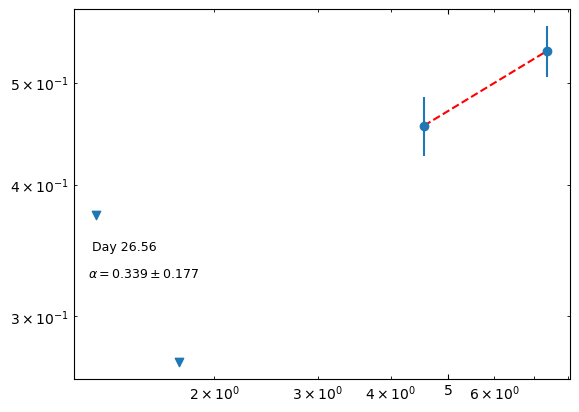

In [46]:
fig,ax = plt.subplots()
mask = df7['Flux Density (mJy)'] > 3 * df7['Uncertainty (mJy)']  # apply detection threshold
mask2 = df7['Flux Density (mJy)'] < 3 * df7['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df7['Freq (GHz)'][mask], df7['Flux Density (mJy)'][mask], yerr=yerr7, fmt='o')
    ax.scatter(df7['Freq (GHz)'][mask2], (df7['Flux Density (mJy)'][mask2] + 3*df7['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 26.56', xy=(60, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df7['Freq (GHz)'][mask], fit_model_weights7(df7['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.339 \\pm 0.177}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

#### Day 41.58

In [48]:
mask = df8['Flux Density (mJy)'] > 3 * df8['Uncertainty (mJy)']  # apply detection threshold
if mask.any():
    x8 = df8['Freq (GHz)'][mask].values.tolist()
    y8 = df8['Flux Density (mJy)'][mask].values.tolist()
    yerr8 = df8['Uncertainty (mJy)'][mask].values.tolist()


In [49]:
yerr8 = error(yerr8, x8, y8)

In [50]:
fit8 = fitting.LevMarLSQFitter(calc_uncertainties=True)

PL8 =  PowerLaw1D(amplitude = y8[0], x_0= x8[0], alpha= -.3,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        #'x_0': (x3[0], x3[0]),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    },
                 fixed={'x_0': True}) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 


    #Fit the data w/o weights
fit_model8 = fit8(PL8, x8, y8)

    #weight is 1/error^2
y_weight8 = 1/ (np.power(yerr8,2))  

    # fit the data using the uncertainties as weights
fit_model_weights8 = fit8(PL8, x8, y8, weights=y_weight8)

fit_model_weights8

<PowerLaw1D(amplitude=0.27589296, x_0=13.5, alpha=-0.17515934)>

In [51]:
fit8.fit_info

{'nfev': 6,
 'fvec': array([ 10.20244476,  -9.61891071, -11.96318393,  42.10544448,
         15.79128952, -15.79111272]),
 'fjac': array([[-3.99155797e+03,  2.38431105e-01,  9.99660990e-02,
          8.81759285e-02,  5.41482806e-01,  7.41329280e-01],
        [-6.84146593e+02,  4.64693427e+02,  2.88828253e-01,
          3.08673478e-01, -7.76359822e-01, -2.13211783e-01]]),
 'ipvt': array([1, 2], dtype=int32),
 'qtf': array([ 9.64756346e-08, -6.07667987e-04]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 0.00012979, -0.00051817],
        [-0.00051817,  0.00302321]]),
 'njev': 5,
 'cov_x': array([[ 1.98808965e-07, -7.93731596e-07],
        [-7.93731596e-07,  4.63091640e-06]])}

In [52]:
#taking fvec
fvec8 = np.array([ 10.20244476,  -9.61891071, -11.96318393,  42.10544448,
         15.79128952, -15.79111272])
var8 = np.var(fvec8)



param_cov8= np.array([[ 1.98808965e-07, -7.93731596e-07],
        [-7.93731596e-07,  4.63091640e-06]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    #sd3 = np.sqrt(diag[2])
    return(sd1,sd2)#,sd3)

diag8 = stand(param_cov8*var8) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print("The standard deviation is", diag8[1]) #Just showing the standard devation on the slope


The standard deviation is 0.043520412795035414


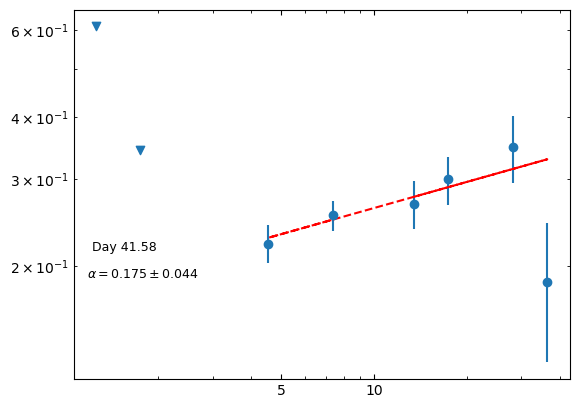

In [53]:
fig,ax = plt.subplots()
mask = df8['Flux Density (mJy)'] > 3 * df8['Uncertainty (mJy)']  # apply detection threshold
mask2 = df8['Flux Density (mJy)'] < 3 * df8['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df8['Freq (GHz)'][mask], df8['Flux Density (mJy)'][mask], yerr=yerr8, fmt='o')
    ax.scatter(df8['Freq (GHz)'][mask2], (df8['Flux Density (mJy)'][mask2] + 3*df8['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 41.58', xy=(60, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df8['Freq (GHz)'][mask], fit_model_weights8(df8['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.175 \\pm 0.044}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

## Day 54.57 - 55.73 (df9)

In [55]:
mask = df9['Flux Density (mJy)'] > 3 * df9['Uncertainty (mJy)']  # apply detection threshold
if mask.any():
    x9 = df9['Freq (GHz)'][mask].values.tolist()
    y9 = df9['Flux Density (mJy)'][mask].values.tolist()
    yerr9 = df9['Uncertainty (mJy)'][mask].values.tolist()

In [56]:
yerr9 = error(yerr9, x9, y9)

In [57]:
fit9 = fitting.LevMarLSQFitter(calc_uncertainties=True)

PL9 =  PowerLaw1D(amplitude = y9[0], x_0= x9[0], alpha= -.3,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        #'x_0': (x3[0], x3[0]),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    },
                 fixed={'x_0': True}) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 


    #Fit the data w/o weights
fit_model9 = fit9(PL9, x9, y9)

    #weight is 1/error^2
y_weight9 = 1/ (np.power(yerr9,2))  

    # fit the data using the uncertainties as weights
fit_model_weights9 = fit9(PL9, x9, y9, weights=y_weight9)

fit_model_weights9

<PowerLaw1D(amplitude=0.33629713, x_0=13.5, alpha=0.27719322)>

In [58]:
fit9.fit_info

{'nfev': 8,
 'fvec': array([-44.64639708, -44.48053359, -16.0973154 ,  -4.72832687,
        -18.81796615, -15.89736736, -29.93659311,  43.65640148]),
 'fjac': array([[-2.73797365e+03,  1.77004854e-01,  9.81978777e-02,
          6.32106622e-02,  5.91994296e-02,  1.51613818e-01,
          5.20795333e-01,  7.99412965e-01],
        [-6.60470331e+02,  3.76026146e+02,  3.29080893e-01,
          2.51764624e-01, -2.52184197e-01, -5.26028726e-01,
         -5.81064576e-01,  5.48279297e-02]]),
 'ipvt': array([1, 2], dtype=int32),
 'qtf': array([ 7.98381642e-07, -3.96764836e-03]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 0.0006959 , -0.00217867],
        [-0.00217867,  0.00903166]]),
 'njev': 7,
 'cov_x': array([[ 5.44935552e-07, -1.70603510e-06],
        [-1.70603510e-06,  7.07235273e-06]])}

In [59]:
#taking fvec
fvec9 = np.array([-44.64639708, -44.48053359, -16.0973154 ,  -4.72832687,
        -18.81796615, -15.89736736, -29.93659311,  43.65640148])
var9 = np.var(fvec9)



param_cov9= np.array([[ 5.44935552e-07, -1.70603510e-06],
        [-1.70603510e-06,  7.07235273e-06]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    #sd3 = np.sqrt(diag[2])
    return(sd1,sd2)#,sd3)

diag9 = stand(param_cov9*var9) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print("The standard deviation is", diag9[1]) #Just showing the standard devation on the slope


The standard deviation is 0.06984883506764077


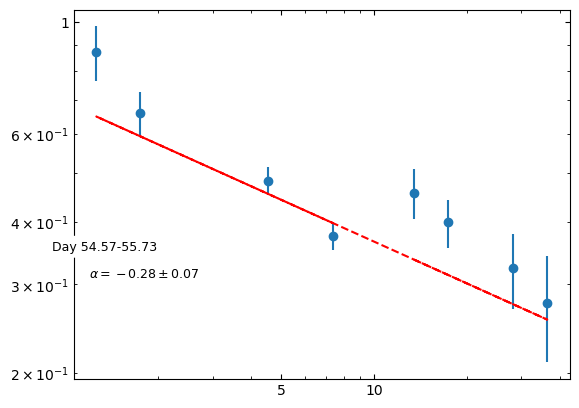

In [60]:
fig,ax = plt.subplots()
mask = df9['Flux Density (mJy)'] > 3 * df9['Uncertainty (mJy)']  # apply detection threshold
mask2 = df9['Flux Density (mJy)'] < 3 * df9['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df9['Freq (GHz)'][mask], df9['Flux Density (mJy)'][mask], yerr=yerr9, fmt='o')
    ax.scatter(df9['Freq (GHz)'][mask2], (df9['Flux Density (mJy)'][mask2] + 3*df9['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 54.57-55.73', xy=(60, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df9['Freq (GHz)'][mask], fit_model_weights9(df9['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.28 \\pm 0.07}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

## Day 65.51 (df11)

In [61]:
mask = df11['Flux Density (mJy)'] > 3 * df11['Uncertainty (mJy)']  # apply detection threshold
if mask.any():
    x11 = df11['Freq (GHz)'][mask].values.tolist()
    y11 = df11['Flux Density (mJy)'][mask].values.tolist()
    yerr11 = df11['Uncertainty (mJy)'][mask].values.tolist()

In [62]:
yerr11 = error(yerr11, x11, y11)

In [63]:
fit11 = fitting.LevMarLSQFitter(calc_uncertainties=True)

PL11 =  PowerLaw1D(amplitude = y11[0], x_0= x11[0], alpha= -.3,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        #'x_0': (x3[0], x3[0]),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    },
                 fixed={'x_0': True}) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 


    #Fit the data w/o weights
fit_model11 = fit11(PL11, x11, y11)

    #weight is 1/error^2
y_weight11 = 1/ (np.power(yerr11,2))  

    # fit the data using the uncertainties as weights
fit_model_weights11 = fit11(PL11, x11, y11, weights=y_weight11)

fit_model_weights11

<PowerLaw1D(amplitude=0.3486389, x_0=1.26, alpha=0.24122679)>

In [64]:
fit11.fit_info

{'nfev': 7,
 'fvec': array([-13.42635584,  19.53822292,  -0.48966896,  -1.46517119,
        -18.00594689,  23.54910036,  -3.15687344]),
 'fjac': array([[-3.13535721e+03,  8.93444758e-02,  5.09028107e-01,
          7.80301717e-01,  2.64633638e-01,  2.20653516e-01,
          5.74607421e-02],
        [ 1.87545824e+03, -4.20764456e+02,  4.73385452e-01,
         -2.54753778e-01, -5.01583562e-01, -5.63699651e-01,
         -2.18872457e-01]]),
 'ipvt': array([1, 2], dtype=int32),
 'qtf': array([-4.06478165e-07,  1.74195076e-03]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[0.00061692, 0.00098193],
        [0.00098193, 0.00164157]]),
 'njev': 6,
 'cov_x': array([[2.12270756e-06, 3.37864282e-06],
        [3.37864282e-06, 5.64835402e-06]])}

In [65]:
#taking fvec
fvec11 = np.array([-13.42635584,  19.53822292,  -0.48966896,  -1.46517119,
        -18.00594689,  23.54910036,  -3.15687344])
var11 = np.var(fvec11)



param_cov11= np.array([[2.12270756e-06, 3.37864282e-06],
        [3.37864282e-06, 5.64835402e-06]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    #sd3 = np.sqrt(diag[2])
    return(sd1,sd2)#,sd3)

diag11 = stand(param_cov11*var11) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print("The standard deviation is", diag11[1]) #Just showing the standard devation on the slope


The standard deviation is 0.034170324911584865


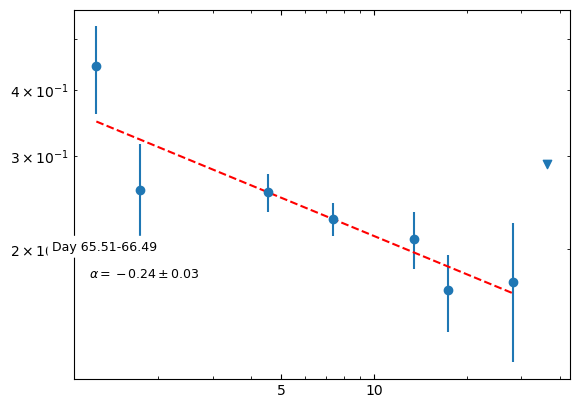

In [66]:
fig,ax = plt.subplots()
mask = df11['Flux Density (mJy)'] > 3 * df11['Uncertainty (mJy)']  # apply detection threshold
mask2 = df11['Flux Density (mJy)'] < 3 * df11['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df11['Freq (GHz)'][mask], df11['Flux Density (mJy)'][mask], yerr=yerr11, fmt='o')
    ax.scatter(df11['Freq (GHz)'][mask2], (df11['Flux Density (mJy)'][mask2] + 3*df11['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 65.51-66.49', xy=(60, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df11['Freq (GHz)'][mask], fit_model_weights11(df11['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.24 \\pm 0.03}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

## Day 78.463 (df13)

In [67]:
mask = df13['Flux Density (mJy)'] > 3 * df13['Uncertainty (mJy)']  # apply detection threshold
if mask.any():
    x13 = df13['Freq (GHz)'][mask].values.tolist()
    y13 = df13['Flux Density (mJy)'][mask].values.tolist()
    yerr13 = df13['Uncertainty (mJy)'][mask].values.tolist()

In [68]:
yerr13 = error(yerr13, x13, y13)

In [69]:
fit13 = fitting.LevMarLSQFitter(calc_uncertainties=True)

PL13 =  PowerLaw1D(amplitude = y13[0], x_0= x13[0], alpha= -.3,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        #'x_0': (x3[0], x3[0]),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    },
                 fixed={'x_0': True}) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 


    #Fit the data w/o weights
fit_model13 = fit13(PL13, x13, y13)

    #weight is 1/error^2
y_weight13 = 1/ (np.power(yerr13,2))  

    # fit the data using the uncertainties as weights
fit_model_weights13 = fit13(PL13, x13, y13, weights=y_weight13)

fit_model_weights13

<PowerLaw1D(amplitude=0.15734792, x_0=4.55, alpha=0.1446789)>

In [70]:
fit13.fit_info

{'nfev': 7,
 'fvec': array([-31.07549812,  30.17309246,  12.12349022, -46.77974398,
        -17.49529858]),
 'fjac': array([[-4.92735222e+03,  7.40175147e-01,  3.86503215e-01,
          2.27259817e-01,  5.13082595e-02],
        [ 3.88824238e+02,  3.05246356e+02,  7.39091555e-01,
          5.81065589e-01,  1.94111353e-01]]),
 'ipvt': array([1, 2], dtype=int32),
 'qtf': array([ 1.96602416e-06, -6.11998395e-03]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[0.00016266, 0.00127531],
        [0.00127531, 0.01616133]]),
 'njev': 6,
 'cov_x': array([[1.08019276e-07, 8.46912896e-07],
        [8.46912896e-07, 1.07324537e-05]])}

In [71]:
#taking fvec
fvec13 = np.array([-31.07549812,  30.17309246,  12.12349022, -46.77974398,
        -17.49529858])
var13 = np.var(fvec13)



param_cov13= np.array([[1.08019276e-07, 8.46912896e-07],
        [8.46912896e-07, 1.07324537e-05]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    #sd3 = np.sqrt(diag[2])
    return(sd1,sd2)#,sd3)

diag13 = stand(param_cov13*var13) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print("The standard deviation is", diag13[1]) #Just showing the standard devation on the slope


The standard deviation is 0.09213273276606208


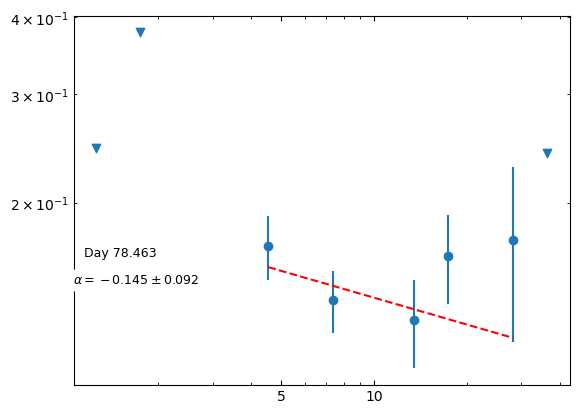

In [72]:
fig,ax = plt.subplots()
mask = df13['Flux Density (mJy)'] > 3 * df13['Uncertainty (mJy)']  # apply detection threshold
mask2 = df13['Flux Density (mJy)'] < 3 * df13['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df13['Freq (GHz)'][mask], df13['Flux Density (mJy)'][mask], yerr=yerr13, fmt='o')
    ax.scatter(df13['Freq (GHz)'][mask2], (df13['Flux Density (mJy)'][mask2] + 3*df13['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 78.463', xy=(60, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df13['Freq (GHz)'][mask], fit_model_weights13(df13['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.145 \\pm 0.092}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

## Day 93.46 (df14)

In [73]:
mask = df14['Flux Density (mJy)'] > 3 * df14['Uncertainty (mJy)']  # apply detection threshold
if mask.any():
    x14 = df14['Freq (GHz)'][mask].values.tolist()
    y14 = df14['Flux Density (mJy)'][mask].values.tolist()
    yerr14 = df14['Uncertainty (mJy)'][mask].values.tolist()

In [74]:
yerr14 = error(yerr14, x14, y14)

In [75]:
fit14= fitting.LevMarLSQFitter(calc_uncertainties=True)

PL14 =  PowerLaw1D(amplitude = y14[0], x_0= x14[0], alpha= -5.5,
                  bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        #'x_0': (x3[0], x3[0]),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    },
                 fixed={'x_0': True}) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 


    #Fit the data w/o weights
fit_model14 = fit14(PL14, x14, y14)

    #weight is 1/error^2
y_weight14 = 1/ (np.power(yerr14,2))  

    # fit the data using the uncertainties as weights
fit_model_weights14 = fit14(PL14, x14, y14, weights=y_weight14)

fit_model_weights14

<PowerLaw1D(amplitude=0.0727, x_0=4.55, alpha=0.05475567)>

In [76]:
fit14.fit_info

{'nfev': 9,
 'fvec': array([0., 0.]),
 'fjac': array([[-3.68789572e+03,  8.65971381e-01],
        [ 9.72407023e+01,  5.61559539e+01]]),
 'ipvt': array([1, 2], dtype=int32),
 'qtf': array([-3.51143644e-11, -2.02783462e-11]),
 'message': 'The relative error between two consecutive iterates is at most 0.000000',
 'ierr': 2,
 'param_jac': None,
 'param_cov': None,
 'njev': 8,
 'cov_x': array([[2.93995181e-07, 8.36137761e-06],
        [8.36137761e-06, 3.17108865e-04]])}

In [77]:
#taking fvec
fvec14 = np.array([0.0000000e+00, 9.4920063e-14])
var14 = np.var(fvec14)



param_cov14= np.array([[2.93995181e-07, 8.36137761e-06],
        [8.36137761e-06, 3.17108865e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    #sd3 = np.sqrt(diag[2])
    return(sd1,sd2)#,sd3)

diag14 = stand(param_cov14)#*var14) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print("The standard deviation is", diag14[1]) #Just showing the standard devation on the slope


The standard deviation is 0.017807550786113176


In [78]:
alpha_err14 = two_points(y14,x14,yerr14)
print(alpha_err14)

(-0.054755671768581815, 0.8358521859860464)


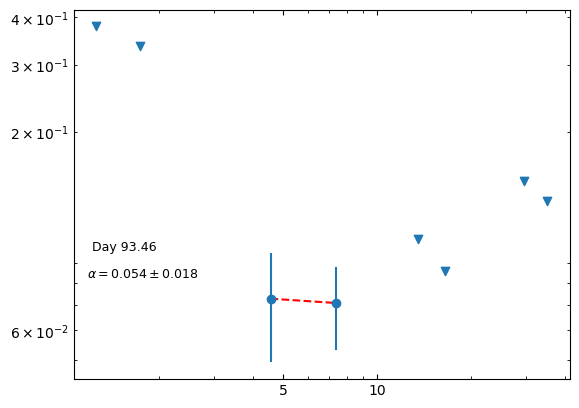

In [79]:
fig,ax = plt.subplots()
mask = df14['Flux Density (mJy)'] > 3 * df14['Uncertainty (mJy)']  # apply detection threshold
mask2 = df14['Flux Density (mJy)'] < 3 * df14['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df14['Freq (GHz)'][mask], df14['Flux Density (mJy)'][mask], yerr=yerr14, fmt='o')
    ax.scatter(df14['Freq (GHz)'][mask2], (df14['Flux Density (mJy)'][mask2] + 3*df14['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 93.46', xy=(60, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df14['Freq (GHz)'][mask], fit_model_weights14(df14['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.054 \\pm 0.018}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

In [80]:
mask = df15['Flux Density (mJy)'] > 3 * df15['Uncertainty (mJy)']
mask2 = df15['Flux Density (mJy)'] < 3 * df15['Uncertainty (mJy)']  # apply non-detection threshold
yerr15 = (df15['Uncertainty (mJy)'][mask].values.tolist(), df15['Freq (GHz)'][mask].values.tolist(), df15['Flux Density (mJy)'][mask].values.tolist())

In [81]:
yerr15

([0.0157], [13.5], [0.0587])

# All together now

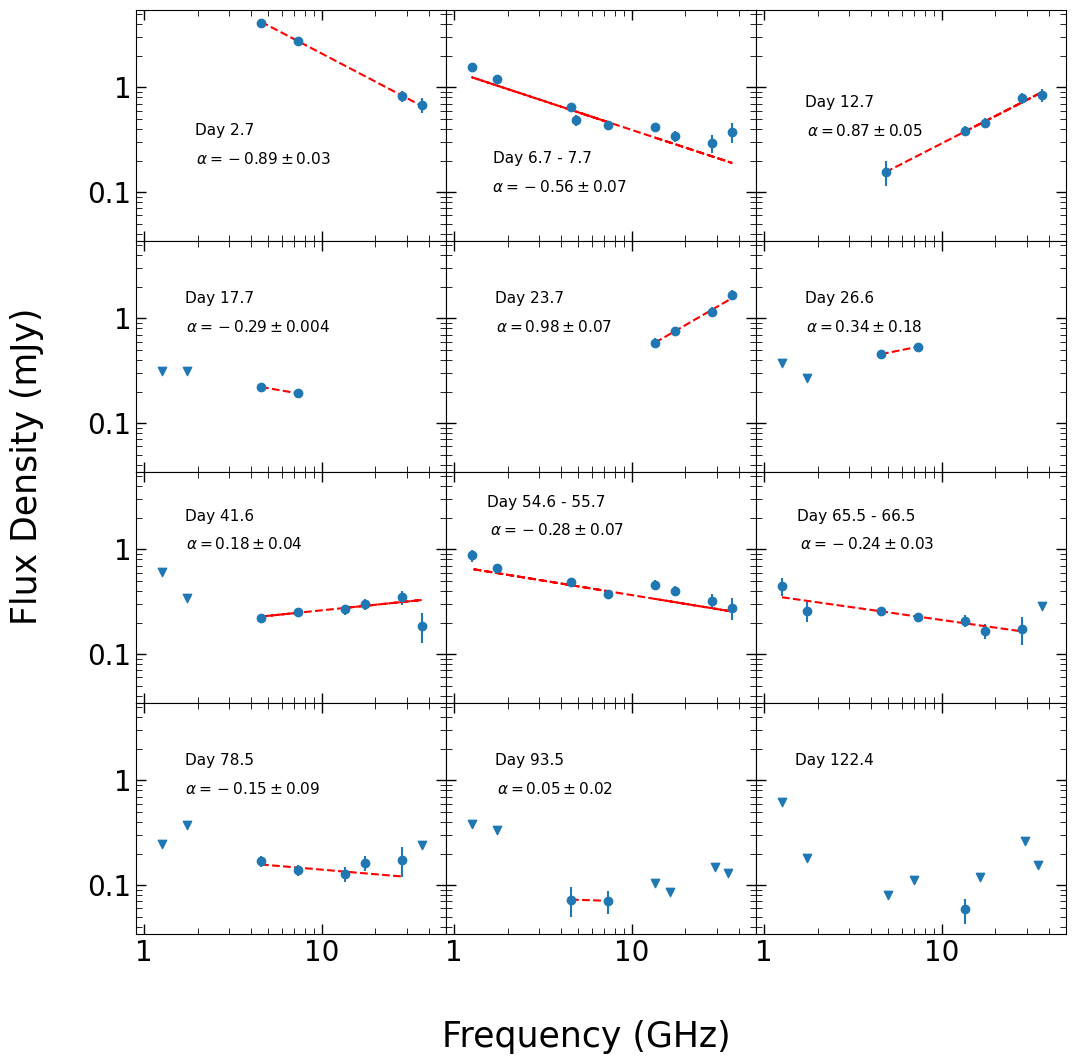

In [82]:
#four by four

fig, ax = plt.subplots(4, 3, sharex='all', sharey='all',squeeze=True, width_ratios=None, height_ratios=None)
fig.set_size_inches(12,12)
fig.subplots_adjust(hspace=0, wspace=0)


mask = df1['Flux Density (mJy)'] > 3 * df1['Uncertainty (mJy)']  # apply detection threshold
mask2 = df1['Flux Density (mJy)'] < 3 * df1['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[0,0].errorbar(df1['Freq (GHz)'][mask], df1['Flux Density (mJy)'][mask], yerr=yerr1, fmt='o')
    ax[0,0].scatter(df1['Freq (GHz)'][mask2], (df1['Flux Density (mJy)'][mask2] + 3*df1['Uncertainty (mJy)'][mask2]), marker='v')
    ax[0,0].set_xscale('log')
    ax[0,0].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'], fontsize = 20)
    ax[0,0].set_yscale('log')
    ax[0,0].set_yticks([0.1,1, 5, 10, 20], labels=['0.1','1', '5', '10', '20'], fontsize = 20)
    ax[0,0].annotate('Day 2.7', xy=(85, 85), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[0,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[0,0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

    ax[0,0].plot(df1['Freq (GHz)'][mask], fit_model_weights1(df1['Freq (GHz)'][mask]), 'r--')
    ax[0,0].annotate('${\u03B1 = -0.89 \\pm 0.03}$', xy=(140, 65), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

mask = df2['Flux Density (mJy)'] > 3 * df2['Uncertainty (mJy)']  # apply detection threshold
mask2 = df2['Flux Density (mJy)'] < 3 * df2['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[0,1].errorbar(df2['Freq (GHz)'][mask], df2['Flux Density (mJy)'][mask], yerr=yerr2, fmt='o')
    ax[0,1].scatter(df2['Freq (GHz)'][mask2], (df2['Flux Density (mJy)'][mask2] + 3*df2['Uncertainty (mJy)'][mask2]), marker='v')
    ax[0,1].set_xscale('log')
    ax[0,1].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax[0,1].set_yscale('log')
    ax[0,1].set_yticks([1, 5, 10, 20], labels=['1', '5', '10', '20'])
    ax[0,1].annotate('Day 6.7 - 7.7', xy=(105, 65), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[0,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[0,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

    ax[0,1].plot(df2['Freq (GHz)'][mask], fit_model_weights2(df2['Freq (GHz)'][mask]), 'r--')
    ax[0,1].annotate('${\u03B1 = -0.56 \\pm 0.07}$', xy=(130, 45), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

mask = df4['Flux Density (mJy)'] > 3 * df4['Uncertainty (mJy)']  # apply detection threshold
mask2 = df4['Flux Density (mJy)'] < 3 * df4['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[0,2].errorbar(df4['Freq (GHz)'][mask], df4['Flux Density (mJy)'][mask], yerr=yerr4, fmt='o')
    ax[0,2].scatter(df4['Freq (GHz)'][mask2], (df4['Flux Density (mJy)'][mask2] + 3*df4['Uncertainty (mJy)'][mask2]), marker='v')
    ax[0,2].set_xscale('log')
    ax[0,2].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax[0,2].set_yscale('log')
    ax[0,2].set_yticks([1, 5, 10, 20], labels=['1', '5', '10', '20'])
    ax[0,2].annotate('Day 12.7', xy=(85, 105), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[0,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[0,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

    ax[0,2].plot(df4['Freq (GHz)'][mask], fit_model_weights4(df4['Freq (GHz)'][mask]), 'r--')
    ax[0,2].annotate('${\u03B1 = 0.87 \\pm 0.05}$', xy=(120, 85), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


#row 2
mask = df5['Flux Density (mJy)'] > 3 * df5['Uncertainty (mJy)']  # apply detection threshold
mask2 = df5['Flux Density (mJy)'] < 3 * df5['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[1,0].errorbar(df5['Freq (GHz)'][mask], df5['Flux Density (mJy)'][mask], yerr=yerr5, fmt='o')
    ax[1,0].scatter(df5['Freq (GHz)'][mask2], (df5['Flux Density (mJy)'][mask2] + 3*df5['Uncertainty (mJy)'][mask2]), marker='v')
    ax[1,0].set_xscale('log')
    ax[1,0].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'], fontsize = 20)
    ax[1,0].set_yscale('log')
    ax[1,0].set_yticks([1, 5, 10, 20], labels=['1', '5', '10', '20'], fontsize = 20)
    ax[1,0].annotate('Day 17.7', xy=(85, 130), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[1,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[1,0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

    ax[1,0].plot(df5['Freq (GHz)'][mask], fit_model_weights5(df5['Freq (GHz)'][mask]), 'r--')
    ax[1,0].annotate('${\u03B1 = -0.29 \\pm 0.004}$', xy=(140, 110), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

mask = df6['Flux Density (mJy)'] > 3 * df6['Uncertainty (mJy)']  # apply detection threshold
mask2 = df6['Flux Density (mJy)'] < 3 * df6['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[1,1].errorbar(df6['Freq (GHz)'][mask], df6['Flux Density (mJy)'][mask], yerr=yerr6, fmt='o')
    ax[1,1].scatter(df6['Freq (GHz)'][mask2], (df6['Flux Density (mJy)'][mask2] + 3*df6['Uncertainty (mJy)'][mask2]), marker='v')
    ax[1,1].set_xscale('log')
    ax[1,1].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax[1,1].set_yscale('log')
    ax[1,1].set_yticks([1, 5, 10, 20], labels=['1', '5', '10', '20'])
    ax[1,1].annotate('Day 23.7', xy=(85, 130), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[1,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[1,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

    ax[1,1].plot(df6['Freq (GHz)'][mask], fit_model_weights6(df6['Freq (GHz)'][mask]), 'r--')
    ax[1,1].annotate('${\u03B1 = 0.98 \\pm 0.07}$', xy=(120, 110), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

mask = df7['Flux Density (mJy)'] > 3 * df7['Uncertainty (mJy)']  # apply detection threshold
mask2 = df7['Flux Density (mJy)'] < 3 * df7['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[1,2].errorbar(df7['Freq (GHz)'][mask], df7['Flux Density (mJy)'][mask], yerr=yerr7, fmt='o')
    ax[1,2].scatter(df7['Freq (GHz)'][mask2], (df7['Flux Density (mJy)'][mask2] + 3*df7['Uncertainty (mJy)'][mask2]), marker='v')
    ax[1,2].set_xscale('log')
    ax[1,2].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax[1,2].set_yscale('log')
    ax[1,2].set_yticks([1, 5, 10, 20], labels=['1', '5', '10', '20'])
    ax[1,2].annotate('Day 26.6', xy=(85, 130), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[1,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[1,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
    ax[1,2].plot(df7['Freq (GHz)'][mask], fit_model_weights7(df7['Freq (GHz)'][mask]), 'r--')
    ax[1,2].annotate('${\u03B1 = 0.34 \\pm 0.18}$', xy=(120, 110), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))



#row 3
mask = df8['Flux Density (mJy)'] > 3 * df8['Uncertainty (mJy)']  # apply detection threshold
mask2 = df8['Flux Density (mJy)'] < 3 * df8['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[2,0].errorbar(df8['Freq (GHz)'][mask], df8['Flux Density (mJy)'][mask], yerr=yerr8, fmt='o')
    ax[2,0].scatter(df8['Freq (GHz)'][mask2], (df8['Flux Density (mJy)'][mask2] + 3*df8['Uncertainty (mJy)'][mask2]), marker='v')
    ax[2,0].set_xscale('log')
    ax[2,0].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'], fontsize=20)
    ax[2,0].set_yscale('log')
    ax[2,0].set_yticks([1, 5, 10, 20], labels=['1', '5', '10', '20'], fontsize=20)
    ax[2,0].annotate('Day 41.6', xy=(85, 140), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[2,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[2,0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

    ax[2,0].plot(df8['Freq (GHz)'][mask], fit_model_weights8(df8['Freq (GHz)'][mask]), 'r--')
    ax[2,0].annotate('${\u03B1 = 0.18 \\pm 0.04}$', xy=(120, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


mask = df9['Flux Density (mJy)'] > 3 * df9['Uncertainty (mJy)']  # apply detection threshold
mask2 = df9['Flux Density (mJy)'] < 3 * df9['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[2,1].errorbar(df9['Freq (GHz)'][mask], df9['Flux Density (mJy)'][mask], yerr=yerr9, fmt='o')
    ax[2,1].scatter(df9['Freq (GHz)'][mask2], (df9['Flux Density (mJy)'][mask2] + 3*df9['Uncertainty (mJy)'][mask2]), marker='v')
    ax[2,1].set_xscale('log')
    ax[2,1].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'], fontsize = 20)
    ax[2,1].set_yscale('log')
    ax[2,1].set_yticks([1, 5, 10, 20], labels=['1', '5', '10', '20'], fontsize = 20)
    ax[2,1].annotate('Day 54.6 - 55.7', xy=(115, 150), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[2,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[2,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

    ax[2,1].plot(df9['Freq (GHz)'][mask], fit_model_weights9(df9['Freq (GHz)'][mask]), 'r--')
    ax[2,1].annotate('${\u03B1 = -0.28 \\pm 0.07}$', xy=(128, 130), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


mask = df11['Flux Density (mJy)'] > 3 * df11['Uncertainty (mJy)']  # apply detection threshold
mask2 = df11['Flux Density (mJy)'] < 3 * df11['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[2,2].errorbar(df11['Freq (GHz)'][mask], df11['Flux Density (mJy)'][mask], yerr=yerr11, fmt='o')
    ax[2,2].scatter(df11['Freq (GHz)'][mask2], (df11['Flux Density (mJy)'][mask2] + 3*df11['Uncertainty (mJy)'][mask2]), marker='v')
    ax[2,2].set_xscale('log')
    ax[2,2].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'], fontsize=20)
    ax[2,2].set_yscale('log')
    ax[2,2].set_yticks([1, 5, 10, 20], labels=['1', '5', '10', '20'], fontsize=20)
    ax[2,2].annotate('Day 65.5 - 66.5', xy=(115, 140), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[2,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[2,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

    ax[2,2].plot(df11['Freq (GHz)'][mask], fit_model_weights11(df11['Freq (GHz)'][mask]), 'r--')
    ax[2,2].annotate('${\u03B1 = -0.24 \\pm 0.03}$', xy=(128, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))



#fourth one
mask = df13['Flux Density (mJy)'] > 3 * df13['Uncertainty (mJy)']  # apply detection threshold
mask2 = df13['Flux Density (mJy)'] < 3 * df13['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[3,0].errorbar(df13['Freq (GHz)'][mask], df13['Flux Density (mJy)'][mask], yerr=yerr13, fmt='o')
    ax[3,0].scatter(df13['Freq (GHz)'][mask2], (df13['Flux Density (mJy)'][mask2] + 3*df13['Uncertainty (mJy)'][mask2]), marker='v')
    ax[3,0].set_xscale('log')
    ax[3,0].set_xticks([1,  10], labels=['1',  '10'], fontsize = 20)
    ax[3,0].set_xlim(left=0.9)
    ax[3,0].set_yscale('log')
    ax[3,0].set_yticks([1,  10], labels=['1',  '10'], fontsize = 20)
    ax[3,0].annotate('Day 78.5', xy=(85, 130), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[3,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[3,0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

    ax[3,0].plot(df13['Freq (GHz)'][mask], fit_model_weights13(df13['Freq (GHz)'][mask]), 'r--')
    ax[3,0].annotate('${\u03B1 = -0.15 \\pm 0.09}$', xy=(133, 110), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

mask = df14['Flux Density (mJy)'] > 3 * df14['Uncertainty (mJy)']  # apply detection threshold
mask2 = df14['Flux Density (mJy)'] < 3 * df14['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[3,1].errorbar(df14['Freq (GHz)'][mask], df14['Flux Density (mJy)'][mask], yerr=yerr14, fmt='o')
    ax[3,1].scatter(df14['Freq (GHz)'][mask2], (df14['Flux Density (mJy)'][mask2] + 3*df14['Uncertainty (mJy)'][mask2]), marker='v')
    ax[3,1].set_xscale('log')
    ax[3,1].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'], fontsize = 20)
    ax[3,1].set_xlim(left=0.9)
    ax[3,1].set_yscale('log')
    ax[3,1].set_yticks([1, 5, 10, 20], labels=['1', '5', '10', '20'], fontsize = 20)
    ax[3,1].annotate('Day 93.5', xy=(85, 130), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[3,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[3,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

    ax[3,1].plot(df14['Freq (GHz)'][mask], fit_model_weights14(df14['Freq (GHz)'][mask]), 'r--')
    ax[3,1].annotate('${\u03B1 = 0.05 \\pm 0.02}$', xy=(120, 110), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

mask = df15['Flux Density (mJy)'] > 3 * df15['Uncertainty (mJy)']
mask2 = df15['Flux Density (mJy)'] < 3 * df15['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():
    ax[3,2].errorbar(df15['Freq (GHz)'][mask], df15['Flux Density (mJy)'][mask], yerr=df15['Uncertainty (mJy)'][mask], fmt='o')
    ax[3,2].scatter(df15['Freq (GHz)'][mask2], (df15['Flux Density (mJy)'][mask2] + 3*df15['Uncertainty (mJy)'][mask2]), marker='v')
    ax[3,2].set_xscale('log')
    ax[3,2].set_xticks([1, 10], labels=['1', '10'], fontsize = 20)
    ax[3,2].set_xlim(left=0.9)
    ax[3,2].set_yscale('log')
    ax[3,2].set_yticks([0.1,1], labels=['0.1','1'], fontsize = 20)
    ax[3,2].annotate('Day 122.4', xy=(85, 130), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[3,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[3,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)



fig.supxlabel("Frequency (GHz)", fontsize = 25)
fig.supylabel("Flux Density (mJy)", fontsize = 25)
plt.savefig("V1535Sco_SI.png")
#plt.legend()
plt.show();